In [1]:
import sys, os, platform, json, hashlib, warnings, time, gc
from pathlib import Path
from contextlib import contextmanager
from collections import Counter
from datetime import datetime, timezone
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score, log_loss)

try:
    import xgboost
    from xgboost import XGBClassifier
except Exception as exc:
    raise RuntimeError(
        "XGBoost could not load. On macOS run 'brew install libomp' in Terminal, "
        "restart the kernel, and check that Python and Homebrew architectures match. "
        "See section 1. Original error: " + str(exc)
    ) from exc

VERSIONS = {'python': sys.version.split()[0], 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
            'xgboost': xgboost.__version__, 'joblib': joblib.__version__}
print('Kernel:', sys.executable, '| Architecture:', platform.machine())
display(pd.Series(VERSIONS, name='version').to_frame())
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})


Kernel: /Users/symbat/PycharmProjects/RMT_IoT/.venv/bin/python | Architecture: arm64


,version
python,3.9.6
numpy,2.0.2
pandas,2.3.3
scikit-learn,1.6.1
xgboost,2.1.4
joblib,1.5.3


In [2]:
SEED = 42
N_SPLITS = 5
THREADS = min(4, os.cpu_count() or 1)
CHUNK_SIZE = 50_000
DATA_PATH = None  # e.g. Path.home() / 'Downloads/CICIOT23.zip', or an extracted CICIOT23 folder
MAX_ROWS = {'train':60_000, 'validation':30_000, 'test':50_000}
MIN_TRAIN_PER_CLASS = 100
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
EXPORT_DIR = Path.cwd() / 'assignment3_results' / RUN_ID
EXPORT_DIR.mkdir(parents=True, exist_ok=False)
FIG_DIR = EXPORT_DIR / 'figures'
FIG_DIR.mkdir()
print('Results folder:', EXPORT_DIR.resolve())

Results folder: /Users/symbat/PycharmProjects/RMT_IoT/.venv/assignment3_results/20261028T055247_833424Z


In [3]:
FEATURES = ['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight']

CLASS_NAMES = ['Benign', 'DDoS', 'DoS', 'Recon', 'Web-based', 'Brute Force', 'Spoofing', 'Mirai']
CLASS_TO_ID = {name:i for i,name in enumerate(CLASS_NAMES)}
CLASS_IDS = np.arange(len(CLASS_NAMES))
RAW_TO_FAMILY = {'Backdoor_Malware': 'Web-based', 'BenignTraffic': 'Benign', 'BrowserHijacking': 'Web-based', 'CommandInjection': 'Web-based', 'DDoS-ACK_Fragmentation': 'DDoS', 'DDoS-HTTP_Flood': 'DDoS', 'DDoS-ICMP_Flood': 'DDoS', 'DDoS-ICMP_Fragmentation': 'DDoS', 'DDoS-PSHACK_Flood': 'DDoS', 'DDoS-RSTFINFlood': 'DDoS', 'DDoS-SYN_Flood': 'DDoS', 'DDoS-SlowLoris': 'DDoS', 'DDoS-SynonymousIP_Flood': 'DDoS', 'DDoS-TCP_Flood': 'DDoS', 'DDoS-UDP_Flood': 'DDoS', 'DDoS-UDP_Fragmentation': 'DDoS', 'DNS_Spoofing': 'Spoofing', 'DictionaryBruteForce': 'Brute Force', 'DoS-HTTP_Flood': 'DoS', 'DoS-SYN_Flood': 'DoS', 'DoS-TCP_Flood': 'DoS', 'DoS-UDP_Flood': 'DoS', 'MITM-ArpSpoofing': 'Spoofing', 'Mirai-greeth_flood': 'Mirai', 'Mirai-greip_flood': 'Mirai', 'Mirai-udpplain': 'Mirai', 'Recon-HostDiscovery': 'Recon', 'Recon-OSScan': 'Recon', 'Recon-PingSweep': 'Recon', 'Recon-PortScan': 'Recon', 'SqlInjection': 'Web-based', 'Uploading_Attack': 'Web-based', 'VulnerabilityScan': 'Recon', 'XSS': 'Web-based'}
INSPECTED_ARCHIVE_SHA256 = '807b34c270f643ad6f5fcba909d9c1f321a8d514b6b511b3d30fe6f1c54ef9b2'
INSPECTED_ROWS = {'train': 5491971, 'validation': 1176851, 'test': 1176851}
assert len(FEATURES) == 46 and len(RAW_TO_FAMILY) == 34
display(pd.DataFrame({"raw_label":list(RAW_TO_FAMILY), "family":list(RAW_TO_FAMILY.values())}))


,raw_label,family
0,Backdoor_Malware,Web-based
1,BenignTraffic,Benign
2,BrowserHijacking,Web-based
3,CommandInjection,Web-based
4,DDoS-ACK_Fragmentation,DDoS
5,DDoS-HTTP_Flood,DDoS
6,DDoS-ICMP_Flood,DDoS
7,DDoS-ICMP_Fragmentation,DDoS
8,DDoS-PSHACK_Flood,DDoS
9,DDoS-RSTFINFlood,DDoS


In [4]:
def choose_data_path(value):
    if value is not None:
        p = Path(value).expanduser().resolve()
        if not p.exists():
            raise FileNotFoundError(f'DATA_PATH does not exist: {p}')
        return p
    candidates = [Path.cwd() / 'CICIOT23', Path.cwd() / 'CICIOT23(1).zip',
                  Path.cwd() / 'CICIOT23.zip',
                  Path.home() / 'PycharmProjects/prototype/CICIOT23',
                  Path.home() / 'Downloads/CICIOT23(1).zip',
                  Path.home() / 'Downloads/CICIOT23.zip',
                  Path('/mnt/data/CICIOT23(1).zip'), Path('/mnt/data/CICIOT23.zip')]
    for p in candidates:
        if p.exists():
            return p.resolve()
    raise FileNotFoundError('Set DATA_PATH to CICIOT23.zip or the extracted CICIOT23 folder.')


DATA_PATH = choose_data_path(DATA_PATH)
IS_ZIP = DATA_PATH.is_file() and DATA_PATH.suffix.lower() == '.zip'
SOURCES, source_inventory = {}, []
if IS_ZIP:
    with ZipFile(DATA_PATH) as z:
        names = [i.filename for i in z.infolist() if not i.is_dir()
                 and '__MACOSX' not in Path(i.filename).parts
                 and not Path(i.filename).name.startswith('._')]
        for split in MAX_ROWS:
            matches = [n for n in names if Path(n).name.lower() == f'{split}.csv']
            if len(matches) != 1:
                raise ValueError(f'Expected exactly one {split}.csv, found {matches}')
            SOURCES[split] = matches[0]
            info = z.getinfo(matches[0])
            source_inventory.append({'split': split, 'source': matches[0],
                                     'bytes': info.file_size, 'zip_crc32': info.CRC})
elif DATA_PATH.is_dir():
    for split in MAX_ROWS:
        matches = [p for p in DATA_PATH.rglob('*.csv') if p.name.lower() == f'{split}.csv'
                   and '__MACOSX' not in p.parts and not p.name.startswith('._')]
        if len(matches) != 1:
            raise ValueError(f'Expected exactly one {split}.csv, found {matches}')
        SOURCES[split] = matches[0]
        source_inventory.append({'split': split, 'source': str(matches[0]),
                                 'bytes': matches[0].stat().st_size})
else:
    raise ValueError('DATA_PATH must be a ZIP or a folder containing the three CSVs.')


@contextmanager
def open_split(split):
    if IS_ZIP:
        with ZipFile(DATA_PATH) as z:
            with z.open(SOURCES[split]) as handle:
                yield handle
    else:
        with open(SOURCES[split], 'rb') as handle:
            yield handle


def read_chunks(split):
    with open_split(split) as handle:
        reader = pd.read_csv(handle, chunksize=CHUNK_SIZE, encoding='utf-8-sig',
                             dtype={c: 'float64' for c in FEATURES},
                             float_precision='round_trip', on_bad_lines='error')
        for chunk in reader:
            if list(chunk.columns) != FEATURES + ['label']:
                raise ValueError(f'Schema mismatch in {split}: {list(chunk.columns)}')
            labels = chunk['label'].astype('string').str.strip()
            if labels.isna().any():
                raise ValueError(f'Missing target in {split}; targets are never imputed.')
            unknown = sorted(set(labels) - set(RAW_TO_FAMILY))
            if unknown:
                raise ValueError(f'Unmapped labels in {split}: {unknown}')
            chunk['label'] = labels
            chunk['family'] = labels.map(RAW_TO_FAMILY)
            yield chunk


print('Using:', DATA_PATH)
display(pd.DataFrame(source_inventory))
if IS_ZIP:
    digest = hashlib.sha256()
    with open(DATA_PATH, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    ACTIVE_ARCHIVE_SHA256 = digest.hexdigest()
    print('ZIP SHA256:', ACTIVE_ARCHIVE_SHA256)
    print('Matches inspected archive:', ACTIVE_ARCHIVE_SHA256 == INSPECTED_ARCHIVE_SHA256)
else:
    ACTIVE_ARCHIVE_SHA256 = None
    print('Using extracted CSVs; runtime row counts/schema are checked below.')


Using: /Users/symbat/PycharmProjects/RMT_IoT/.venv/CICIOT23.zip


,split,source,bytes,zip_crc32
0,train,CICIOT23/train/train.csv,1623446296,2071069906
1,validation,CICIOT23/validation/validation.csv,347921865,457594534
2,test,CICIOT23/test/test.csv,347958926,1731845692


ZIP SHA256: 807b34c270f643ad6f5fcba909d9c1f321a8d514b6b511b3d30fe6f1c54ef9b2
Matches inspected archive: True


train: 5,491,971 rows; 33.6 seconds
validation: 1,176,851 rows; 7.2 seconds
test: 1,176,851 rows; 7.4 seconds


,rows,raw_labels,missing_cells,infinite_cells,matches_inspected_row_count
train,5491971,34,0,0,True
validation,1176851,34,0,0,True
test,1176851,34,0,0,True


,train,validation,test
Benign,129538,27519,27709
DDoS,3998500,857523,855981
DoS,950656,203450,204245
Recon,41617,9015,8812
Web-based,2821,657,626
Brute Force,1541,290,319
Spoofing,57530,12306,12410
Mirai,309768,66091,66749


,train,validation,test
DDoS-ICMP_Flood,848088,182011,180447
DDoS-UDP_Flood,637558,136466,136717
DDoS-TCP_Flood,528499,113888,113735
DDoS-PSHACK_Flood,481254,102985,103326
DDoS-SYN_Flood,478653,102644,102208
DDoS-RSTFINFlood,475441,101563,101819
DDoS-SynonymousIP_Flood,422083,90795,90480
DoS-UDP_Flood,390422,83446,83627
DoS-TCP_Flood,314174,67056,67697
DoS-SYN_Flood,237573,51115,51116


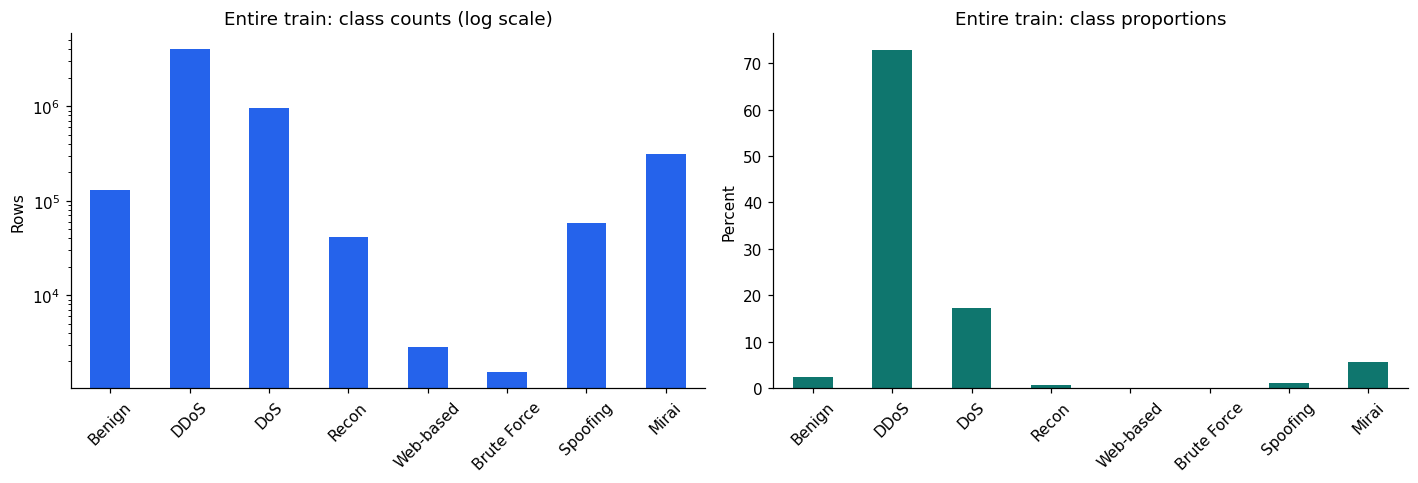

In [5]:
def scan_split(split):
    started = time.perf_counter()
    raw_counts, family_counts = Counter(), Counter()
    missing = pd.Series(0, index=FEATURES, dtype='int64')
    infinite = missing.copy()
    n = 0
    for chunk in read_chunks(split):
        n += len(chunk)
        raw_counts.update(chunk['label'].value_counts().to_dict())
        family_counts.update(chunk['family'].value_counts().to_dict())
        values = chunk[FEATURES]
        missing += values.isna().sum()
        infinite += np.isinf(values.to_numpy()).sum(axis=0)
    if set(family_counts) != set(CLASS_NAMES):
        raise ValueError(f'{split} does not contain all eight families: {family_counts}')
    result = {'rows':n, 'raw_counts':dict(raw_counts), 'family_counts':dict(family_counts),
              'missing':missing.to_dict(), 'infinite':infinite.to_dict()}
    print(f'{split}: {n:,} rows; {time.perf_counter()-started:.1f} seconds')
    return result

AUDIT = {split:scan_split(split) for split in MAX_ROWS}
audit_summary = pd.DataFrame({s:{'rows':a['rows'], 'raw_labels':len(a['raw_counts']),
    'missing_cells':sum(a['missing'].values()), 'infinite_cells':sum(a['infinite'].values()),
    'matches_inspected_row_count':a['rows'] == INSPECTED_ROWS[s]} for s,a in AUDIT.items()}).T
family_counts = pd.DataFrame({s:a['family_counts'] for s,a in AUDIT.items()}).reindex(CLASS_NAMES)
raw_counts = pd.DataFrame({s:a['raw_counts'] for s,a in AUDIT.items()}).fillna(0).astype(int)
display(audit_summary)
display(family_counts)
display(raw_counts)
audit_summary.to_csv(EXPORT_DIR / 'full_data_audit.csv')
family_counts.to_csv(EXPORT_DIR / 'full_family_counts.csv')
raw_counts.to_csv(EXPORT_DIR / 'full_raw_label_counts.csv')

fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
family_counts['train'].plot.bar(ax=axes[0], color='#2563eb', logy=True)
axes[0].set(title='Entire train: class counts (log scale)', ylabel='Rows')
(family_counts['train']/family_counts['train'].sum()*100).plot.bar(ax=axes[1], color='#0f766e')
axes[1].set(title='Entire train: class proportions', ylabel='Percent')
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
fig.savefig(FIG_DIR / '01_full_train_class_distribution.png', bbox_inches='tight')
plt.show()


In [6]:
def allocate_quotas(counts, budget, minimum):
    counts = pd.Series(counts).reindex(CLASS_NAMES).astype(int)
    if budget is None or budget >= counts.sum():
        return counts
    if not isinstance(budget, int) or budget <= 0:
        raise ValueError('Budgets must be positive integers or None.')
    lower = counts.clip(upper=minimum)
    if budget < lower.sum():
        raise ValueError('Budget is too small for the requested minimum class coverage.')
    ideal = counts / counts.sum() * budget
    quota = np.maximum(np.floor(ideal).astype(int), lower).astype(int)
    while quota.sum() > budget:
        candidate = (quota - ideal).where(quota > lower, -np.inf).idxmax()
        quota[candidate] -= 1
    while quota.sum() < budget:
        candidate = (ideal - quota).where(quota < counts, -np.inf).idxmax()
        quota[candidate] += 1
    return quota


QUOTAS = {s: allocate_quotas(AUDIT[s]['family_counts'], MAX_ROWS[s],
                             MIN_TRAIN_PER_CLASS if s == 'train' else 1) for s in MAX_ROWS}
display(pd.DataFrame(QUOTAS))


def sample_split(split, quota, seed):
    rng = np.random.default_rng(seed)
    pools = {family: None for family in CLASS_NAMES}
    offset = 0
    for chunk in read_chunks(split):
        chunk['_source_row'] = np.arange(offset, offset + len(chunk), dtype=np.int64)
        chunk['_priority'] = rng.random(len(chunk))
        offset += len(chunk)
        chunk[FEATURES] = chunk[FEATURES].replace([np.inf, -np.inf], np.nan)
        for family, group in chunk.groupby('family', sort=False):
            pool = group if pools[family] is None else pd.concat([pools[family], group], ignore_index=True)
            k = int(quota[family])
            if len(pool) > k:
                keep = np.argpartition(pool['_priority'].to_numpy(), k - 1)[:k]
                pool = pool.iloc[keep]
            pools[family] = pool.copy()
    if offset != AUDIT[split]['rows']:
        raise RuntimeError('Input changed between audit and sampling.')
    result = pd.concat(list(pools.values()), ignore_index=True).drop(columns='_priority')
    result = result.sort_values('_source_row').reset_index(drop=True)
    if not result['family'].value_counts().reindex(CLASS_NAMES).equals(quota):
        raise AssertionError('Sampling quotas were not met.')
    print(f'{split}: selected {len(result):,} real rows from {offset:,}')
    return result


samples = {s: sample_split(s, QUOTAS[s], SEED + i) for i, s in enumerate(MAX_ROWS)}


def fingerprints(frame):
    values = np.array(frame[FEATURES], dtype='<f8', order='C', copy=True)
    values[values == 0] = 0.0  # canonical +0, including original -0
    values[np.isnan(values)] = np.nan  # canonical NaN representation
    return pd.Series([hashlib.sha256(row.tobytes()).hexdigest() for row in values], index=frame.index)


for frame in samples.values():
    frame['_fingerprint'] = fingerprints(frame)

cleaning_log = []


def unique_partition(frame, split):
    conflicts = frame.groupby('_fingerprint')['family'].nunique()
    bad = set(conflicts[conflicts > 1].index)
    ambiguous = frame['_fingerprint'].isin(bad)
    clean = frame.loc[~ambiguous].drop_duplicates('_fingerprint', keep='first').copy()
    cleaning_log.append({'split': split, 'sampled_rows': len(frame),
                         'conflicting_rows_removed': int(ambiguous.sum()),
                         'repeated_rows_removed': int((~ambiguous).sum() - len(clean)),
                         'unique_rows': len(clean)})
    return clean.reset_index(drop=True)


train = unique_partition(samples['train'], 'train')
train_fingerprints = set(train['_fingerprint'])
eval_views, overlap_rows = {}, []
for split in ['validation', 'test']:
    raw = samples[split].copy()
    raw['_overlap_train'] = raw['_fingerprint'].isin(train_fingerprints)
    unique = unique_partition(raw, split)
    overlap_mask = unique['_fingerprint'].isin(train_fingerprints)
    clean = unique.loc[~overlap_mask].reset_index(drop=True)
    eval_views[split] = {'sampled_original': raw, 'unique_unseen': clean}
    for family in CLASS_NAMES:
        overlap_rows.append({'split': split, 'family': family,
                             'sampled_rows': int((raw['family'] == family).sum()),
                             'sampled_overlap_train': int(((raw['family'] == family) & raw['_overlap_train']).sum()),
                             'unique_unseen_rows': int((clean['family'] == family).sum())})
    assert not set(clean['_fingerprint']) & train_fingerprints

cleaning_table = pd.DataFrame(cleaning_log)
overlap_table = pd.DataFrame(overlap_rows)
display(cleaning_table)
display(overlap_table)
cleaning_table.to_csv(EXPORT_DIR / 'cleaning_audit.csv', index=False)
overlap_table.to_csv(EXPORT_DIR / 'evaluation_population_audit.csv', index=False)

sampling_rows = []
for split in MAX_ROWS:
    for family in CLASS_NAMES:
        full_count = AUDIT[split]['family_counts'][family]
        sampling_rows.append({'split': split, 'family': family, 'full_count': full_count,
                              'full_fraction': full_count / AUDIT[split]['rows'],
                              'sample_count': int(QUOTAS[split][family]),
                              'sample_fraction': int(QUOTAS[split][family]) / int(QUOTAS[split].sum())})
sampling_table = pd.DataFrame(sampling_rows)
display(sampling_table)
sampling_table.to_csv(EXPORT_DIR / 'sampling_distribution.csv', index=False)

X = train[FEATURES].copy()
y = train['family'].map(CLASS_TO_ID).to_numpy(dtype=int)
support = pd.Series(y).value_counts().reindex(CLASS_IDS, fill_value=0)
if (support < N_SPLITS).any():
    raise ValueError('Need >=5 cleaned train rows in every class. Increase train budget or minimum.')
assert list(X.columns) == FEATURES and X.shape[1] == 46
assert train['_fingerprint'].is_unique
display(train[FEATURES + ['label', 'family']].head())
display(X.describe().T)
print('Predictors:', X.shape, '| labels:', dict(zip(CLASS_NAMES, support)))


,train,validation,test
Benign,1390,701,1177
DDoS,43658,21860,36367
DoS,10361,5186,8678
Recon,429,230,374
Web-based,100,17,27
Brute Force,100,7,14
Spoofing,603,314,527
Mirai,3359,1685,2836


train: selected 60,000 real rows from 5,491,971
validation: selected 30,000 real rows from 1,176,851
test: selected 50,000 real rows from 1,176,851


,split,sampled_rows,conflicting_rows_removed,repeated_rows_removed,unique_rows
0,train,60000,0,20,59980
1,validation,30000,0,6,29994
2,test,50000,0,7,49993


,split,family,sampled_rows,sampled_overlap_train,unique_unseen_rows
0,validation,Benign,701,0,701
1,validation,DDoS,21860,11,21844
2,validation,DoS,5186,0,5185
3,validation,Recon,230,0,230
4,validation,Web-based,17,0,17
5,validation,Brute Force,7,0,7
6,validation,Spoofing,314,0,314
7,validation,Mirai,1685,1,1684
8,test,Benign,1177,2,1175
9,test,DDoS,36367,18,36343


,split,family,full_count,full_fraction,sample_count,sample_fraction
0,train,Benign,129538,0.023587,1390,0.023167
1,train,DDoS,3998500,0.728063,43658,0.727633
2,train,DoS,950656,0.173099,10361,0.172683
3,train,Recon,41617,0.007578,429,0.007150
4,train,Web-based,2821,0.000514,100,0.001667
5,train,Brute Force,1541,0.000281,100,0.001667
6,train,Spoofing,57530,0.010475,603,0.010050
7,train,Mirai,309768,0.056404,3359,0.055983
8,validation,Benign,27519,0.023384,701,0.023367
9,validation,DDoS,857523,0.728659,21860,0.728667


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label,family
0,0.792572,450056.12,16.55,64.46,439.732525,439.732525,0.0,0.0,0.0,0.0,...,917.67,8.337415e+07,9.5,41.582602,786.764108,326300.196763,0.95,141.55,DDoS-UDP_Fragmentation,DDoS
1,0.000000,54.00,6.00,64.00,32.097193,32.097193,0.0,0.0,0.0,0.0,...,54.00,8.333115e+07,9.5,10.392305,0.000000,0.000000,0.00,141.55,DDoS-PSHACK_Flood,DDoS
2,0.087448,14714.00,16.84,65.91,6856.430332,6856.430332,0.0,0.0,0.0,0.0,...,50.20,8.310236e+07,9.5,10.069209,1.686404,8.015752,0.19,141.55,DDoS-UDP_Flood,DDoS
3,0.000000,53.46,5.94,63.36,25.888288,25.888288,0.0,0.0,1.0,0.0,...,54.06,8.336110e+07,9.5,10.407224,0.505921,0.721418,0.19,141.55,DDoS-SynonymousIP_Flood,DDoS
4,0.000000,0.00,1.00,65.91,12.034701,12.034701,0.0,0.0,0.0,0.0,...,42.00,8.312868e+07,9.5,9.165151,0.000000,0.000000,0.00,141.55,DDoS-ICMP_Flood,DDoS


,count,mean,std,min,25%,50%,75%,max
flow_duration,59980.0,5.499423e+00,4.087683e+02,0.000000,0.000000e+00,0.000000e+00,1.105818e-01,9.943576e+04
Header_Length,59980.0,7.697006e+04,4.555411e+05,0.000000,5.400000e+01,5.400000e+01,2.984150e+02,9.865998e+06
Protocol Type,59980.0,9.009458e+00,8.865119e+00,0.940000,6.000000e+00,6.000000e+00,1.260000e+01,4.700000e+01
Duration,59980.0,6.637947e+01,1.412426e+01,12.000000,6.400000e+01,6.400000e+01,6.400000e+01,2.550000e+02
Rate,59980.0,9.103079e+03,1.016910e+05,0.000000,2.035765e+00,1.541930e+01,1.120393e+02,5.242880e+06
Srate,59980.0,9.103079e+03,1.016910e+05,0.000000,2.035765e+00,1.541930e+01,1.120393e+02,5.242880e+06
Drate,59980.0,2.115769e-06,4.476851e-04,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.080001e-01
fin_flag_number,59980.0,8.702901e-02,2.818799e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
syn_flag_number,59980.0,2.098366e-01,4.071953e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
rst_flag_number,59980.0,9.123041e-02,2.879389e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00


Predictors: (59980, 46) | labels: {'Benign': 1390, 'DDoS': 43643, 'DoS': 10358, 'Recon': 429, 'Web-based': 100, 'Brute Force': 99, 'Spoofing': 603, 'Mirai': 3358}


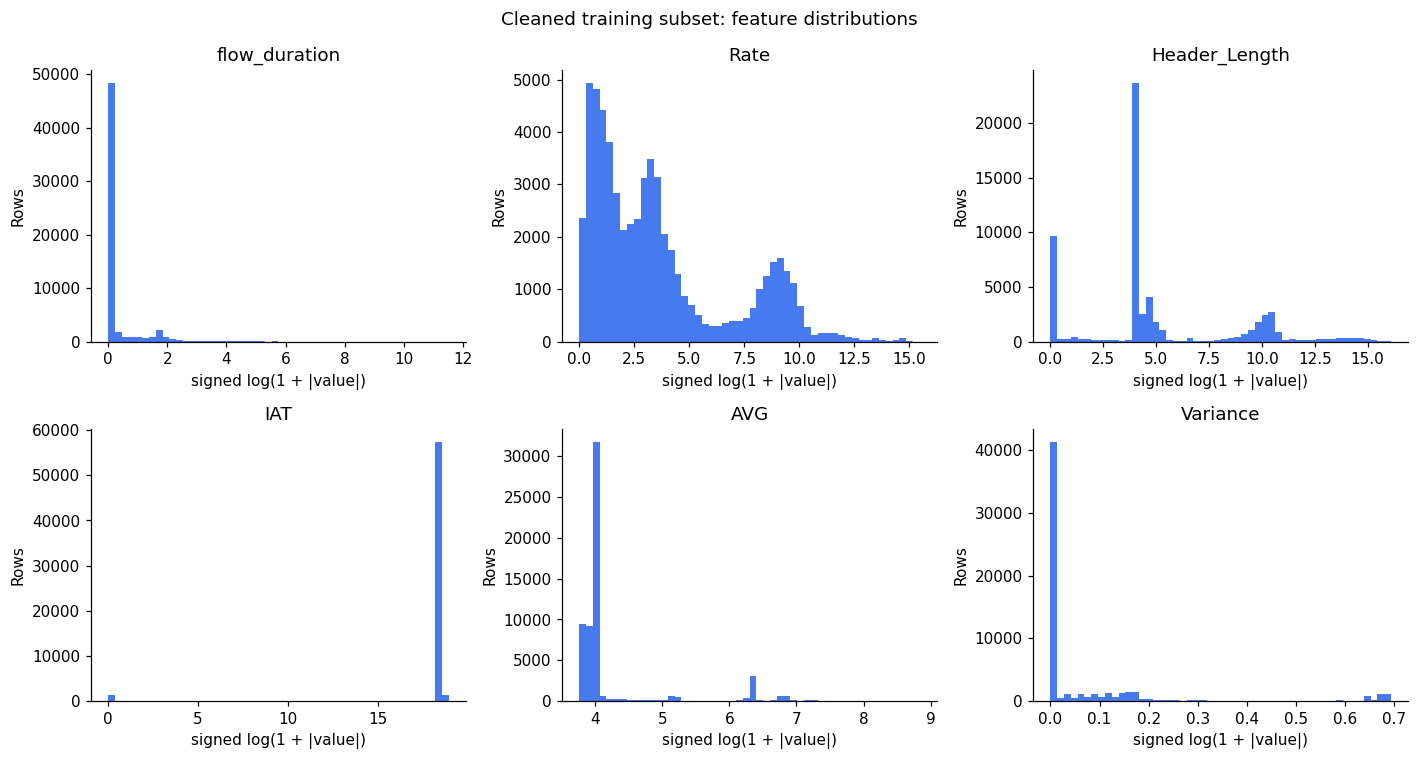

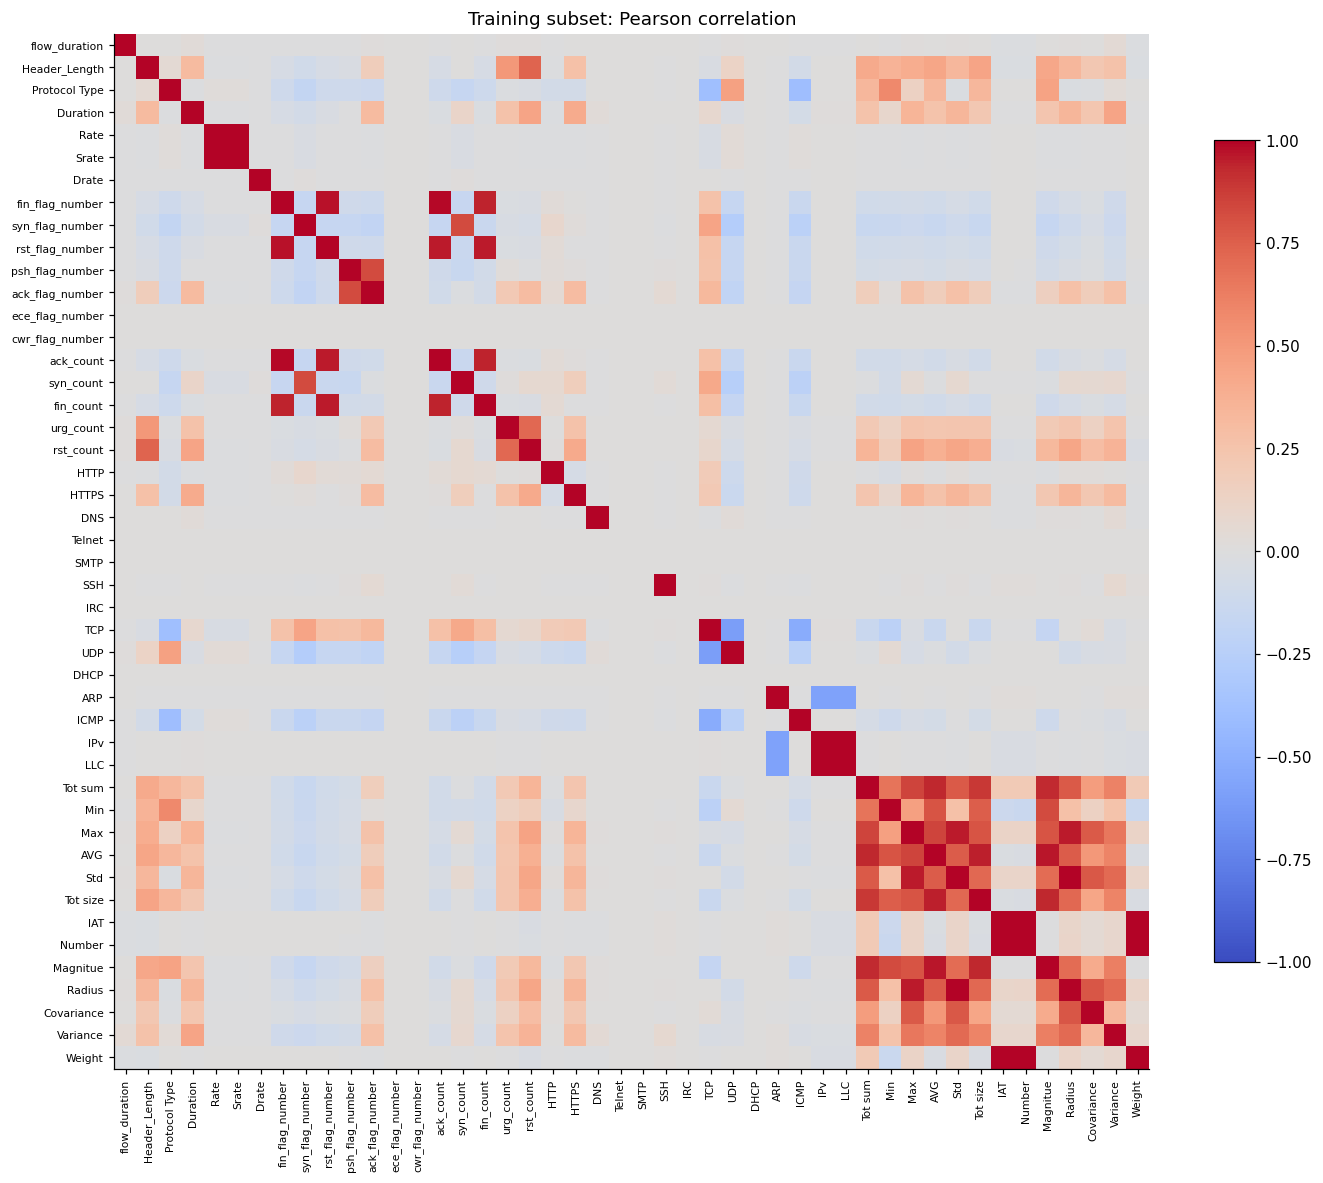

,missing,unique_values,constant_in_subset
flow_duration,0,27483,False
Header_Length,0,17698,False
Protocol Type,0,902,False
Duration,0,2127,False
Rate,0,57756,False
Srate,0,57756,False
Drate,0,3,False
fin_flag_number,0,2,False
syn_flag_number,0,2,False
rst_flag_number,0,2,False


In [7]:
# Train-only feature EDA. No values are altered by these diagnostic plots.
selected_features = ['flow_duration', 'Rate', 'Header_Length', 'IAT', 'AVG', 'Variance']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feature in zip(axes.flat, selected_features):
    finite = X[feature].dropna()
    transformed = np.sign(finite) * np.log1p(np.abs(finite))
    ax.hist(transformed, bins=50, color='#2563eb', alpha=.85)
    ax.set(title=feature, xlabel='signed log(1 + |value|)', ylabel='Rows')
fig.suptitle('Cleaned training subset: feature distributions')
fig.tight_layout()
fig.savefig(FIG_DIR / '02_training_feature_distributions.png', bbox_inches='tight')
plt.show()

corr = X.corr().fillna(0)
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set(xticks=np.arange(len(FEATURES)), yticks=np.arange(len(FEATURES)),
       xticklabels=FEATURES, yticklabels=FEATURES, title='Training subset: Pearson correlation')
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7)
plt.setp(ax.get_yticklabels(), fontsize=7)
fig.colorbar(im, ax=ax, shrink=.75)
fig.tight_layout()
fig.savefig(FIG_DIR / '03_training_correlation.png', bbox_inches='tight')
plt.show()
display(pd.DataFrame({'missing': X.isna().sum(), 'unique_values': X.nunique(),
                      'constant_in_subset': X.nunique(dropna=False) <= 1}))


In [8]:
def pipeline_for(estimator, scaled):
    steps = [('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
             ('nonconstant', VarianceThreshold(threshold=0.0))]
    if scaled:
        steps.append(('scale', StandardScaler()))
    return Pipeline(steps + [('model', estimator)])


MODELS = {
    'Logistic Regression': pipeline_for(LogisticRegression(
        C=1.0, solver='lbfgs', max_iter=2000, tol=1e-4, random_state=SEED), True),
    'kNN': pipeline_for(KNeighborsClassifier(
        n_neighbors=5, weights='distance', algorithm='brute', n_jobs=THREADS), True),
    'Random Forest': pipeline_for(RandomForestClassifier(
        n_estimators=160, max_depth=None, min_samples_leaf=1,
        max_features='sqrt', n_jobs=THREADS, random_state=SEED), False),
    'XGBoost': pipeline_for(XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9,
        colsample_bytree=0.9, objective='multi:softprob', num_class=8,
        eval_metric='mlogloss', tree_method='hist', n_jobs=THREADS,
        random_state=SEED, verbosity=0), False)
}
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X, y))
fold_id = np.full(len(y), -1, dtype=int)
for fold, (fit_idx, val_idx) in enumerate(FOLDS, 1):
    fold_id[val_idx] = fold
    assert not set(train.iloc[fit_idx]['_fingerprint']) & set(train.iloc[val_idx]['_fingerprint'])
    assert set(y[fit_idx]) == set(CLASS_IDS) and set(y[val_idx]) == set(CLASS_IDS)
assert (fold_id > 0).all()
fold_manifest = train[['_source_row', 'label', 'family', '_fingerprint']].copy()
fold_manifest['fold'] = fold_id
fold_manifest.to_csv(EXPORT_DIR / 'training_rows_and_folds.csv', index=False)
display(pd.crosstab(pd.Series(fold_id, name='fold'), pd.Series([CLASS_NAMES[i] for i in y], name='family')))


family,Benign,Brute Force,DDoS,DoS,Mirai,Recon,Spoofing,Web-based
fold,,,,,,,,
1,278,20,8729,2072,671,86,120,20
2,278,20,8729,2071,672,86,120,20
3,278,19,8729,2071,672,86,121,20
4,278,20,8728,2072,672,85,121,20
5,278,20,8728,2072,671,86,121,20


In [9]:
def aligned_proba(estimator, values):
    probabilities = estimator.predict_proba(values)
    aligned = np.zeros((len(values), len(CLASS_NAMES)))
    aligned[:, np.asarray(estimator.classes_, dtype=int)] = probabilities
    if not np.isfinite(aligned).all() or not np.allclose(aligned.sum(axis=1), 1, atol=1e-5):
        raise ValueError('Invalid predicted probabilities.')
    # XGBoost returns float32; remove harmless row-sum rounding after promotion to float64.
    aligned /= aligned.sum(axis=1, keepdims=True)
    return aligned


def score_predictions(truth, predictions, probabilities):
    # Fixed 8-label macro scores; unsupported families receive zero and are visible in the report.
    aucs = [roc_auc_score((truth == c).astype(int), probabilities[:, c])
            for c in CLASS_IDS if 0 < np.sum(truth == c) < len(truth)]
    return {'accuracy': accuracy_score(truth, predictions),
            'balanced_accuracy': balanced_accuracy_score(truth, predictions),
            'precision_macro': precision_score(truth, predictions, labels=CLASS_IDS, average='macro', zero_division=0),
            'recall_macro': recall_score(truth, predictions, labels=CLASS_IDS, average='macro', zero_division=0),
            'f1_macro': f1_score(truth, predictions, labels=CLASS_IDS, average='macro', zero_division=0),
            'f1_weighted': f1_score(truth, predictions, labels=CLASS_IDS, average='weighted', zero_division=0),
            'roc_auc_ovr_macro': float(np.mean(aucs)) if aucs else np.nan,
            'auc_defined_classes': len(aucs),
            'log_loss': log_loss(truth, probabilities, labels=CLASS_IDS)}


def report_frame(truth, predictions):
    report = pd.DataFrame(classification_report(truth, predictions, labels=CLASS_IDS,
                                                target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T
    if 'accuracy' in report.index:
        report.loc['accuracy', ['precision', 'recall']] = np.nan
        report.loc['accuracy', 'support'] = len(truth)
    return report


CV_ROWS, WARNING_ROWS, OOF = [], [], {}
for name, prototype in MODELS.items():
    print(f'--- {name} ---', flush=True)
    predictions = np.full(len(y), -1, dtype=int)
    probabilities = np.full((len(y), len(CLASS_NAMES)), np.nan)
    for fold, (fit_idx, val_idx) in enumerate(FOLDS, 1):
        estimator = clone(prototype)
        with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=THREADS):
            warnings.simplefilter('always')
            started = time.perf_counter()
            estimator.fit(X.iloc[fit_idx], y[fit_idx])
            fit_seconds = time.perf_counter() - started
            started = time.perf_counter()
            fold_pred = estimator.predict(X.iloc[val_idx]).astype(int)
            fold_proba = aligned_proba(estimator, X.iloc[val_idx])
            predict_seconds = time.perf_counter() - started
        for warning in caught:
            WARNING_ROWS.append({'stage': 'CV', 'model': name, 'fold': fold,
                                 'category': warning.category.__name__, 'message': str(warning.message)})
        predictions[val_idx] = fold_pred
        probabilities[val_idx] = fold_proba
        row = {'model': name, 'fold': fold, 'train_rows': len(fit_idx), 'validation_rows': len(val_idx),
               'fit_seconds': fit_seconds, 'predict_seconds': predict_seconds,
               **score_predictions(y[val_idx], fold_pred, fold_proba)}
        CV_ROWS.append(row)
        print(f"Fold {fold}/5: macro-F1={row['f1_macro']:.4f}, accuracy={row['accuracy']:.4f}, "
              f"fit={fit_seconds:.1f}s, predict+proba={predict_seconds:.1f}s, warnings={len(caught)}", flush=True)
        pd.DataFrame(CV_ROWS).to_csv(EXPORT_DIR / 'cv_fold_metrics.csv', index=False)
        del estimator
        gc.collect()
    assert (predictions >= 0).all() and np.isfinite(probabilities).all()
    OOF[name] = {'pred': predictions, 'proba': probabilities}

cv_results = pd.DataFrame(CV_ROWS)
METRICS = ['accuracy', 'balanced_accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
           'f1_weighted', 'roc_auc_ovr_macro', 'log_loss', 'fit_seconds', 'predict_seconds']
summary = cv_results.groupby('model', sort=False)[METRICS].agg(['mean', 'std'])
summary.columns = ['_'.join(parts) for parts in summary.columns]
summary = summary.sort_values('f1_macro_mean', ascending=False, kind='stable')
BEST_NAME = summary.index[0]
summary.to_csv(EXPORT_DIR / 'cv_summary_mean_std.csv')
display(summary.round(4))
print('Winner selected using train CV only:', BEST_NAME)
print('Fold SD describes variation across folds; it is not a confidence interval.')
if WARNING_ROWS:
    display(pd.DataFrame(WARNING_ROWS))
    print('Warnings are retained. A ConvergenceWarning means the LR result may be under-optimized.')


--- Logistic Regression ---
Fold 1/5: macro-F1=0.5944, accuracy=0.8596, fit=1.8s, predict+proba=0.0s, warnings=0
Fold 2/5: macro-F1=0.5286, accuracy=0.8280, fit=1.8s, predict+proba=0.0s, warnings=0
Fold 3/5: macro-F1=0.5521, accuracy=0.8328, fit=1.8s, predict+proba=0.0s, warnings=0
Fold 4/5: macro-F1=0.5276, accuracy=0.8290, fit=1.9s, predict+proba=0.0s, warnings=0
Fold 5/5: macro-F1=0.5192, accuracy=0.8274, fit=1.8s, predict+proba=0.0s, warnings=0
--- kNN ---
Fold 1/5: macro-F1=0.6693, accuracy=0.9385, fit=0.1s, predict+proba=1.2s, warnings=0
Fold 2/5: macro-F1=0.6434, accuracy=0.9336, fit=0.1s, predict+proba=0.9s, warnings=0
Fold 3/5: macro-F1=0.6536, accuracy=0.9352, fit=0.1s, predict+proba=1.0s, warnings=0
Fold 4/5: macro-F1=0.6332, accuracy=0.9290, fit=0.1s, predict+proba=1.0s, warnings=0
Fold 5/5: macro-F1=0.6538, accuracy=0.9321, fit=0.1s, predict+proba=0.9s, warnings=0
--- Random Forest ---
Fold 1/5: macro-F1=0.7162, accuracy=0.9907, fit=1.4s, predict+proba=0.1s, warnings=0
Fol

,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,f1_weighted_mean,f1_weighted_std,roc_auc_ovr_macro_mean,roc_auc_ovr_macro_std,log_loss_mean,log_loss_std,fit_seconds_mean,fit_seconds_std,predict_seconds_mean,predict_seconds_std
model,,,,,,,,,,,,,,,,,,,,
XGBoost,0.9917,0.0005,0.7487,0.0218,0.8047,0.0350,0.7487,0.0218,0.7656,0.0260,0.9912,0.0006,0.9986,0.0001,0.0256,0.0016,2.6724,0.0770,0.1077,0.0049
Random Forest,0.9916,0.0007,0.7342,0.0216,0.8340,0.0380,0.7342,0.0216,0.7560,0.0247,0.9908,0.0008,0.9978,0.0014,0.0332,0.0015,1.3502,0.0501,0.0784,0.0158
kNN,0.9337,0.0035,0.6302,0.0115,0.6972,0.0253,0.6302,0.0115,0.6506,0.0135,0.9320,0.0039,0.8936,0.0076,0.6529,0.0174,0.1098,0.0019,1.0022,0.1003
Logistic Regression,0.8354,0.0137,0.5178,0.0242,0.7016,0.0482,0.5178,0.0242,0.5444,0.0305,0.7926,0.0236,0.9672,0.0013,0.3702,0.0067,1.8179,0.0631,0.0098,0.0023


Winner selected using train CV only: XGBoost
Fold SD describes variation across folds; it is not a confidence interval.


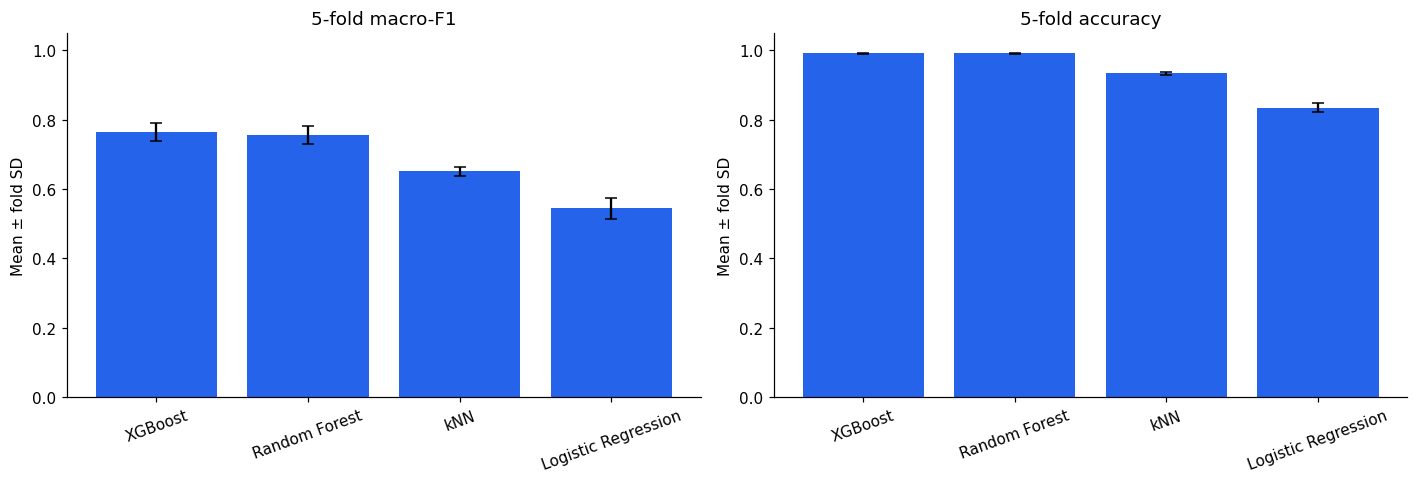

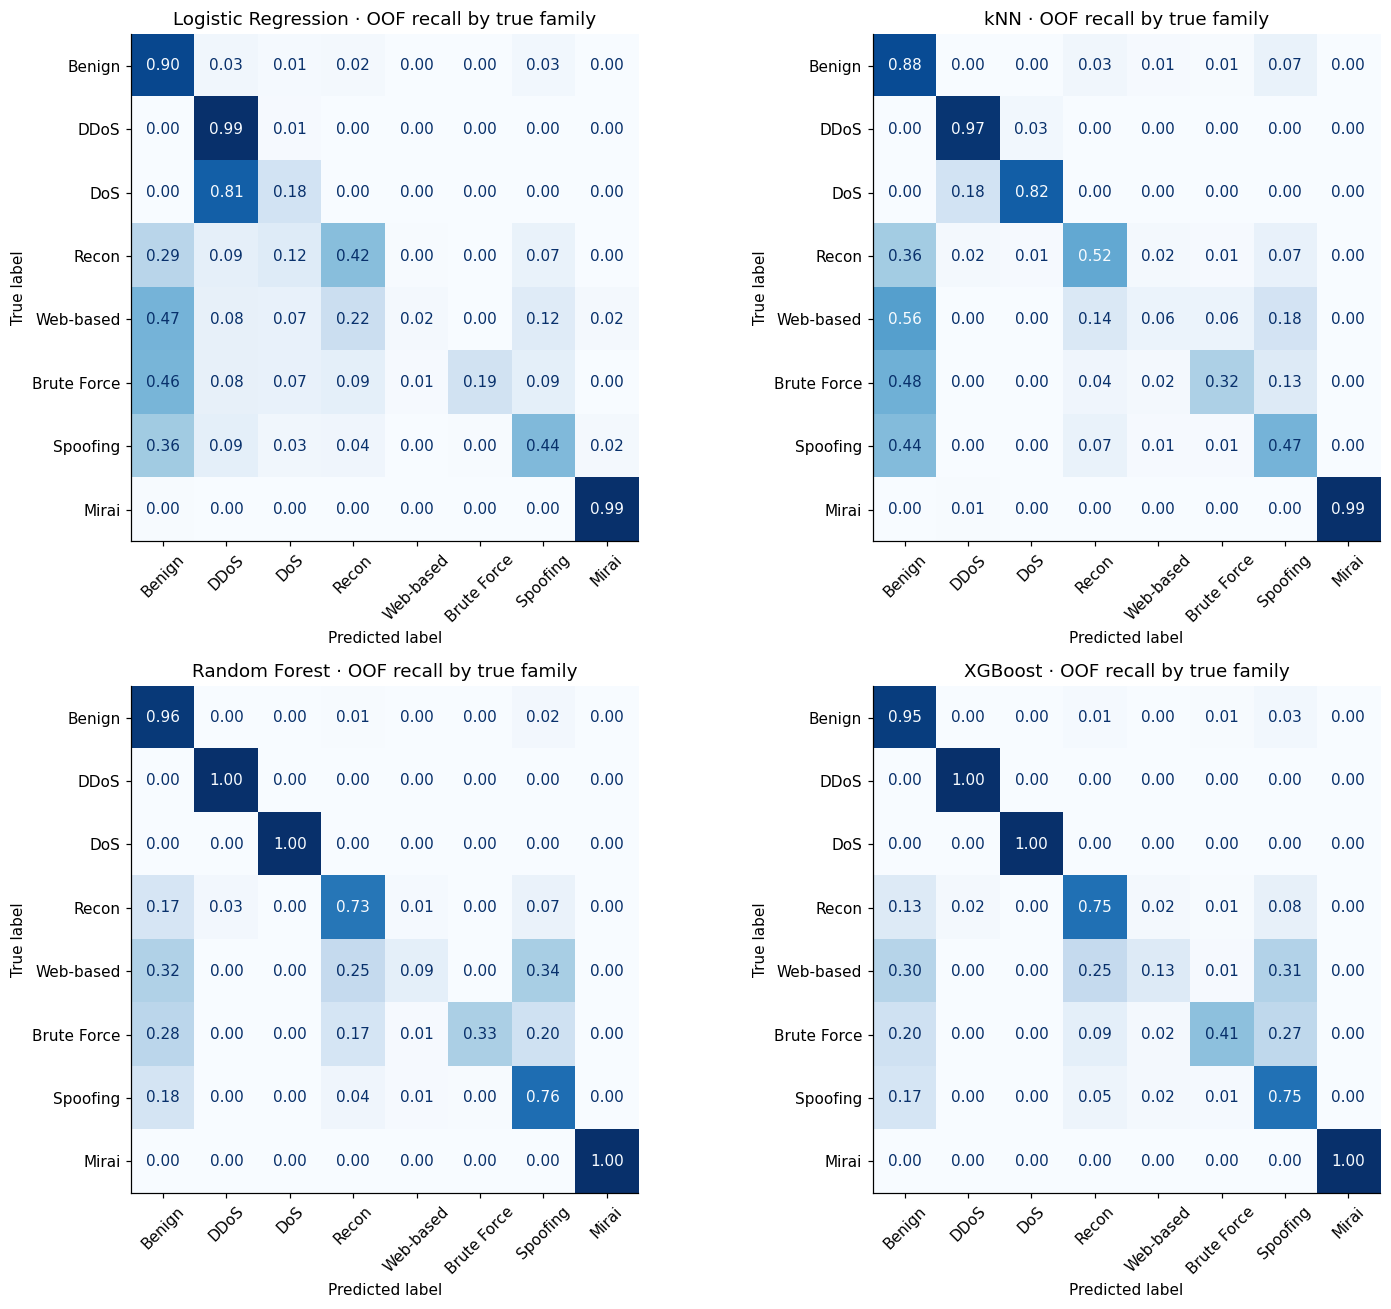

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro,auc_defined_classes,log_loss
model,,,,,,,,,
Logistic Regression,0.8354,0.5178,0.6983,0.5178,0.5457,0.7935,0.9667,8,0.3702
kNN,0.9337,0.6303,0.6958,0.6303,0.6515,0.9320,0.8937,8,0.6529
Random Forest,0.9916,0.7343,0.8273,0.7343,0.7570,0.9908,0.9978,8,0.0332
XGBoost,0.9917,0.7488,0.8049,0.7488,0.7668,0.9912,0.9986,8,0.0256


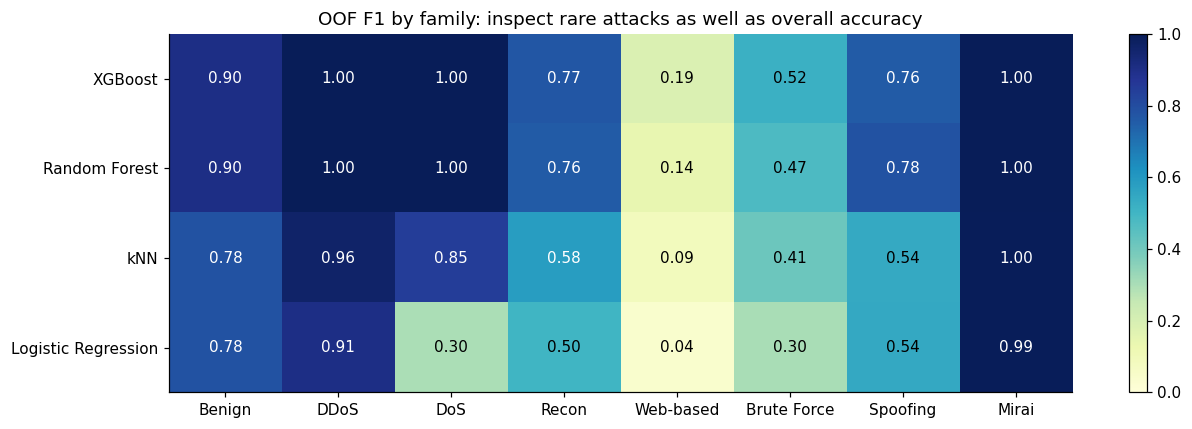

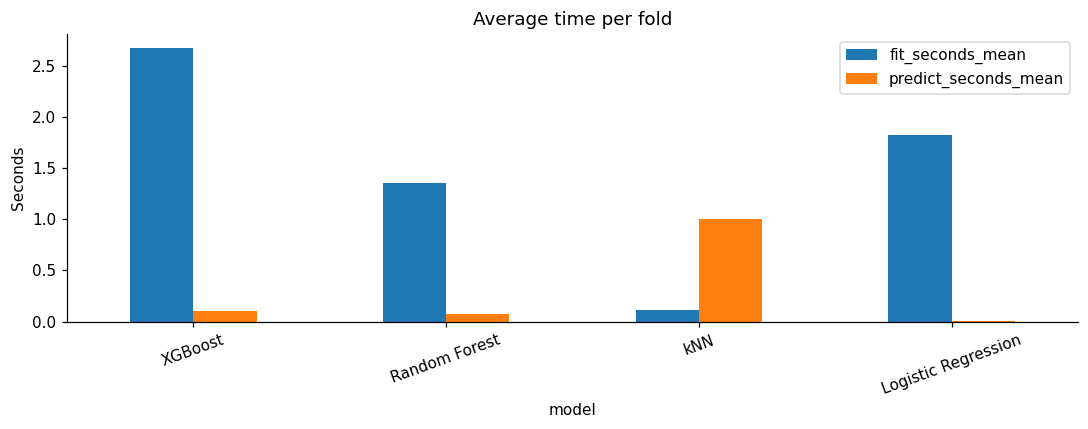

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
for ax, metric, title in zip(axes,['f1_macro','accuracy'],['5-fold macro-F1','5-fold accuracy']):
    values = summary[f'{metric}_mean']
    ax.bar(np.arange(len(values)),values,yerr=summary[f'{metric}_std'],capsize=4,color='#2563eb')
    ax.set(xticks=np.arange(len(values)),xticklabels=summary.index,ylim=(0,1.05),title=title,ylabel='Mean ± fold SD')
    ax.tick_params(axis='x',rotation=20)
fig.tight_layout()
fig.savefig(FIG_DIR / '04_cv_comparison.png',bbox_inches='tight')
plt.show()

oof_rows = []
fig, axes = plt.subplots(2,2,figsize=(14,12))
per_class_f1 = {}
for ax,(name,result) in zip(axes.flat,OOF.items()):
    oof_rows.append({'model':name,**score_predictions(y,result['pred'],result['proba'])})
    report = report_frame(y,result['pred'])
    per_class_f1[name] = report.loc[CLASS_NAMES,'f1-score']
    slug = name.lower().replace(' ','_')
    report.to_csv(EXPORT_DIR / f'oof_classification_report_{slug}.csv')
    cm = confusion_matrix(y,result['pred'],labels=CLASS_IDS,normalize='true')
    ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES).plot(ax=ax,colorbar=False,values_format='.2f',cmap='Blues')
    ax.set_title(name + ' · OOF recall by true family')
    ax.tick_params(axis='x',rotation=45)
fig.tight_layout()
fig.savefig(FIG_DIR / '05_oof_confusion_matrices.png',bbox_inches='tight')
plt.show()
oof_summary = pd.DataFrame(oof_rows).set_index('model')
oof_summary.to_csv(EXPORT_DIR / 'oof_aggregate_metrics.csv')
display(oof_summary.round(4))

per_class_f1 = pd.DataFrame(per_class_f1).T.reindex(summary.index)
fig, ax = plt.subplots(figsize=(12,4))
im = ax.imshow(per_class_f1,vmin=0,vmax=1,cmap='YlGnBu',aspect='auto')
for i in range(len(per_class_f1)):
    for j in range(len(CLASS_NAMES)):
        value = per_class_f1.iloc[i,j]
        ax.text(j,i,f'{value:.2f}',ha='center',va='center',color='white' if value > .55 else 'black')
ax.set(xticks=np.arange(8),xticklabels=CLASS_NAMES,yticks=np.arange(4),
       yticklabels=per_class_f1.index,title='OOF F1 by family: inspect rare attacks as well as overall accuracy')
fig.colorbar(im,ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / '06_per_class_f1.png',bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(10,4))
summary[['fit_seconds_mean','predict_seconds_mean']].plot.bar(ax=ax,rot=20)
ax.set(title='Average time per fold',ylabel='Seconds')
fig.tight_layout()
fig.savefig(FIG_DIR / '07_model_runtime.png',bbox_inches='tight')
plt.show()

In [11]:
final_model = clone(MODELS[BEST_NAME])
started = time.perf_counter()
with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=THREADS):
    warnings.simplefilter('always')
    final_model.fit(X, y)
FINAL_FIT_SECONDS = time.perf_counter() - started
for warning in caught:
    WARNING_ROWS.append({'stage': 'final_fit', 'model': BEST_NAME, 'fold': None,
                         'category': warning.category.__name__, 'message': str(warning.message)})

HOLDOUT_ROWS, HOLDOUT_PREDICTIONS = [], {}
for split in ['validation', 'test']:
    # Predict each original sample once, then derive the clean view from those same predictions.
    raw = eval_views[split]['sampled_original']
    with threadpool_limits(limits=THREADS):
        started = time.perf_counter()
        pred = final_model.predict(raw[FEATURES]).astype(int)
        proba = aligned_proba(final_model, raw[FEATURES])
        seconds = time.perf_counter() - started
    pred_table = raw[['_source_row', 'label', 'family', '_fingerprint', '_overlap_train']].copy()
    pred_table['true_id'] = raw['family'].map(CLASS_TO_ID).to_numpy(dtype=int)
    pred_table['predicted_id'] = pred
    pred_table['predicted_family'] = [CLASS_NAMES[i] for i in pred]
    for c, family in enumerate(CLASS_NAMES):
        pred_table[f'probability_{family}'] = proba[:, c]
    retained_rows = set(eval_views[split]['unique_unseen']['_source_row'])
    pred_table['in_unique_unseen_view'] = pred_table['_source_row'].isin(retained_rows)
    pred_table.to_csv(EXPORT_DIR / f'{split}_predictions.csv', index=False)
    for view, frame in eval_views[split].items():
        mask = pred_table['_source_row'].isin(set(frame['_source_row'])).to_numpy()
        truth = pred_table.loc[mask, 'true_id'].to_numpy()
        if len(truth) == 0:
            raise ValueError(f'No rows remain in {split}/{view}; increase the evaluation budget.')
        row = {'split': split, 'population': view, 'model': BEST_NAME, 'rows': len(truth),
               'original_sample_predict_seconds': seconds,
               **score_predictions(truth, pred[mask], proba[mask])}
        HOLDOUT_ROWS.append(row)
        report = report_frame(truth, pred[mask])
        report.to_csv(EXPORT_DIR / f'{split}_{view}_classification_report.csv')
        HOLDOUT_PREDICTIONS[(split, view)] = {'y': truth, 'pred': pred[mask], 'proba': proba[mask]}
holdout_results = pd.DataFrame(HOLDOUT_ROWS)
display(holdout_results.round(4))
holdout_results.to_csv(EXPORT_DIR / 'heldout_metrics.csv', index=False)
print('Final train-only fit time:', round(FINAL_FIT_SECONDS, 2), 'seconds')
print('Final test report — unique feature vectors unseen in fitted train:')
test_result = HOLDOUT_PREDICTIONS[('test', 'unique_unseen')]
display(report_frame(test_result['y'], test_result['pred']).round(4))


,split,population,model,rows,original_sample_predict_seconds,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro,auc_defined_classes,log_loss
0,validation,sampled_original,XGBoost,30000,0.2813,0.9931,0.7644,0.7539,0.7644,0.7507,0.9930,0.9988,8,0.0197
1,validation,unique_unseen,XGBoost,29982,0.2813,0.9931,0.7644,0.7539,0.7644,0.7507,0.9930,0.9988,8,0.0197
2,test,sampled_original,XGBoost,50000,0.4444,0.9930,0.7747,0.7668,0.7747,0.7633,0.9929,0.9988,8,0.0202
3,test,unique_unseen,XGBoost,49968,0.4444,0.9930,0.7713,0.7635,0.7713,0.7597,0.9929,0.9988,8,0.0202


Final train-only fit time: 3.22 seconds
Final test report — unique feature vectors unseen in fitted train:


,precision,recall,f1-score,support
Benign,0.8812,0.9472,0.9130,1175.0
DDoS,0.9994,0.9998,0.9996,36343.0
DoS,0.9993,0.9990,0.9991,8676.0
Recon,0.8230,0.7086,0.7615,374.0
Web-based,0.2500,0.1481,0.1860,27.0
Brute Force,0.3333,0.6154,0.4324,13.0
Spoofing,0.8219,0.7533,0.7861,527.0
Mirai,0.9996,0.9989,0.9993,2833.0
accuracy,NaN,NaN,0.9930,49968.0
macro avg,0.7635,0.7713,0.7597,49968.0


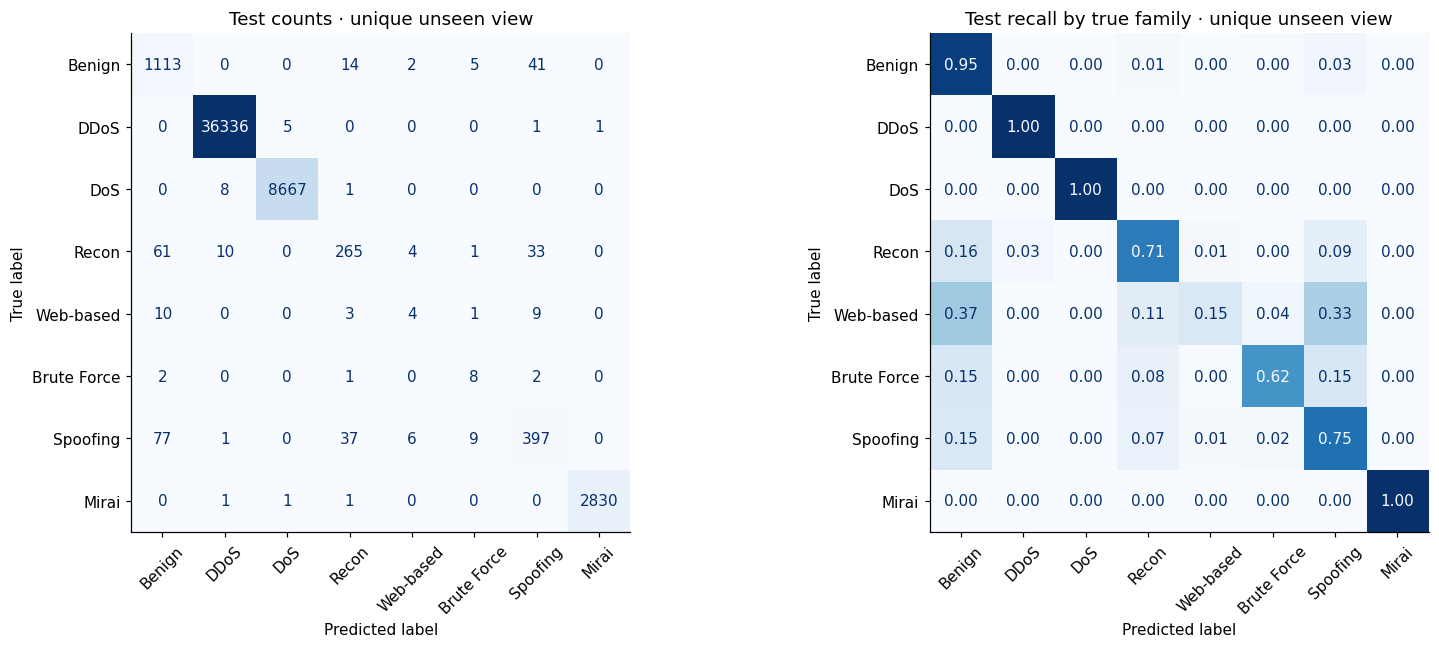

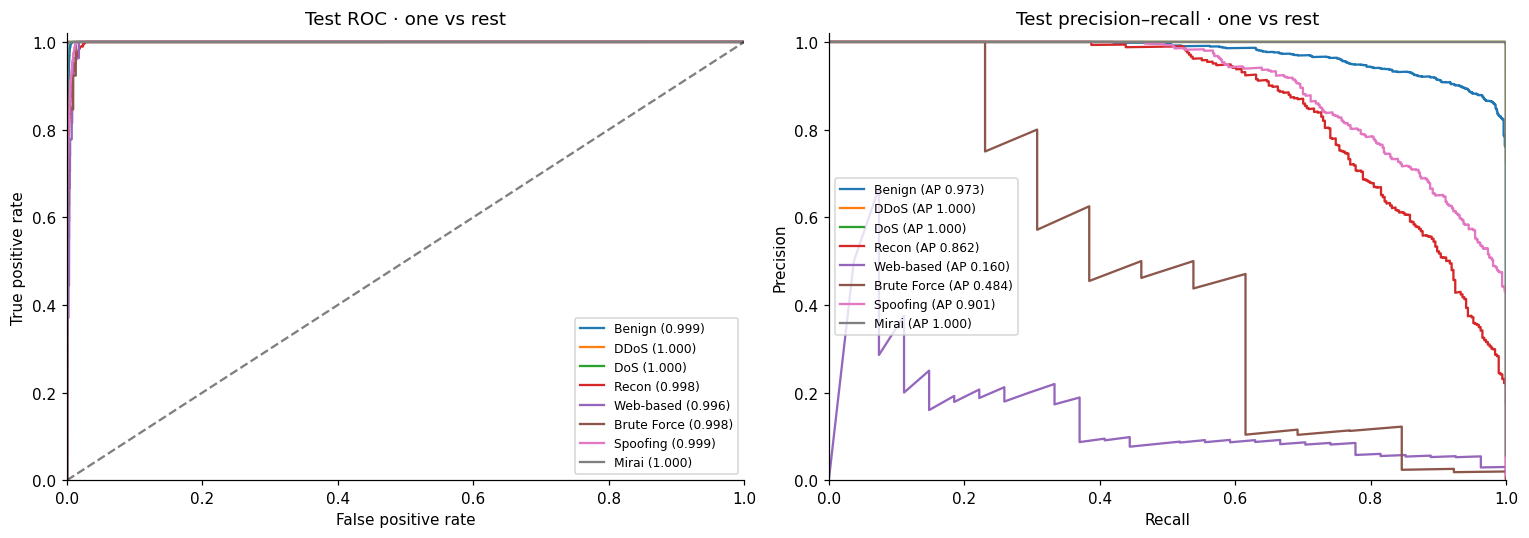

,family,support,prevalence,roc_auc_ovr,average_precision,no_skill_precision_baseline
0,Benign,1175,0.023515,0.999394,0.973395,0.023515
1,DDoS,36343,0.727325,0.999999,0.999999,0.727325
2,DoS,8676,0.173631,0.999999,0.999996,0.173631
3,Recon,374,0.007485,0.998028,0.861610,0.007485
4,Web-based,27,0.000540,0.996386,0.159663,0.000540
5,Brute Force,13,0.000260,0.997927,0.484042,0.000260
6,Spoofing,527,0.010547,0.998585,0.901398,0.010547
7,Mirai,2833,0.056696,1.000000,0.999997,0.056696


In [12]:
fig, axes = plt.subplots(1,2,figsize=(15,6))
for ax,norm,title in zip(axes,[None,'true'],['Test counts','Test recall by true family']):
    cm = confusion_matrix(test_result['y'],test_result['pred'],labels=CLASS_IDS,normalize=norm)
    ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES).plot(
        ax=ax,colorbar=False,cmap='Blues',values_format='d' if norm is None else '.2f')
    ax.set_title(title + ' · unique unseen view')
    ax.tick_params(axis='x',rotation=45)
fig.tight_layout()
fig.savefig(FIG_DIR / '08_test_confusion_matrix.png',bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1,2,figsize=(14,5))
curve_rows = []
for c,family in enumerate(CLASS_NAMES):
    binary = (test_result['y'] == c).astype(int)
    scores = test_result['proba'][:,c]
    if binary.min() == binary.max():
        print('ROC/PR skipped (only one binary class present):',family)
        continue
    fpr,tpr,_ = roc_curve(binary,scores)
    precision,recall,_ = precision_recall_curve(binary,scores)
    auc = roc_auc_score(binary,scores)
    ap = average_precision_score(binary,scores)
    prevalence = binary.mean()
    axes[0].plot(fpr,tpr,label=f'{family} ({auc:.3f})')
    axes[1].plot(recall,precision,label=f'{family} (AP {ap:.3f})')
    curve_rows.append({'family':family,'support':int(binary.sum()),'prevalence':prevalence,
                       'roc_auc_ovr':auc,'average_precision':ap,
                       'no_skill_precision_baseline':prevalence})
axes[0].plot([0,1],[0,1],'k--',alpha=.5)
axes[0].set(title='Test ROC · one vs rest',xlabel='False positive rate',ylabel='True positive rate')
axes[1].set(title='Test precision–recall · one vs rest',xlabel='Recall',ylabel='Precision')
for ax in axes:
    ax.legend(fontsize=8,loc='best')
    ax.set_xlim(0,1)
    ax.set_ylim(0,1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / '09_test_roc_pr.png',bbox_inches='tight')
plt.show()
display(pd.DataFrame(curve_rows))
pd.DataFrame(curve_rows).to_csv(EXPORT_DIR / 'test_roc_pr_metrics.csv',index=False)


In [13]:
primary = holdout_results.query("split == 'test' and population == 'unique_unseen'").iloc[0]
best_cv = summary.loc[BEST_NAME]
test_report = report_frame(test_result['y'],test_result['pred']).loc[CLASS_NAMES]
weakest = test_report.loc[test_report['support'] > 0,'f1-score'].idxmin()
display(Markdown(
    f"**Selected model:** {BEST_NAME}. Mean 5-fold macro-F1: "
    f"{best_cv['f1_macro_mean']:.4f} ± {best_cv['f1_macro_std']:.4f} (fold SD). "
    f"Held-out test, unique unseen view: **{int(primary['rows']):,} rows**, "
    f"accuracy **{primary['accuracy']:.4f}**, macro-F1 **{primary['f1_macro']:.4f}**, "
    f"balanced accuracy **{primary['balanced_accuracy']:.4f}**. "
    f"The lowest per-class F1 in this run is **{weakest}** "
    f"({test_report.loc[weakest,'f1-score']:.4f}, support {int(test_report.loc[weakest,'support'])}). "
    "These are subset results after the documented cleaning and overlap policy."
))

bundle = {'pipeline':final_model,'model_name':BEST_NAME,'feature_columns':FEATURES,
          'class_names':CLASS_NAMES,'class_to_id':CLASS_TO_ID,'versions':VERSIONS}
joblib.dump(bundle, EXPORT_DIR / 'best_model_pipeline.joblib')
for filename, payload in [('feature_columns.json',FEATURES),('class_mapping.json',
    {'raw_to_family':RAW_TO_FAMILY,'family_to_id':CLASS_TO_ID}),('full_scan_audit.json',AUDIT)]:
    (EXPORT_DIR / filename).write_text(json.dumps(payload,indent=2),encoding='utf-8')

for name,result in OOF.items():
    table = fold_manifest.copy()
    table['true_id'] = y
    table['predicted_id'] = result['pred']
    table['predicted_family'] = [CLASS_NAMES[i] for i in result['pred']]
    for c,family in enumerate(CLASS_NAMES):
        table[f'probability_{family}'] = result['proba'][:,c]
    table.to_csv(EXPORT_DIR / ('oof_predictions_'+name.lower().replace(' ','_')+'.csv'),index=False)

pd.DataFrame(WARNING_ROWS,columns=['stage','model','fold','category','message']).to_csv(
    EXPORT_DIR / 'training_warnings.csv',index=False)
manifest = {'run_started_utc':RUN_STARTED_UTC,'source':str(DATA_PATH),
    'source_inventory':source_inventory,'active_archive_sha256':ACTIVE_ARCHIVE_SHA256,
    'inspected_archive_sha256':INSPECTED_ARCHIVE_SHA256,'versions':VERSIONS,
    'seed':SEED,'n_splits':N_SPLITS,'threads':THREADS,'budgets':MAX_ROWS,
    'minimum_train_rows_per_class':MIN_TRAIN_PER_CLASS,'cleaned_train_rows':len(train),
    'selected_model':BEST_NAME,'selection_metric':'mean 5-fold macro-F1 on train only',
    'model_parameters':{name:{k:str(v) for k,v in model.get_params().items()}
                        for name,model in MODELS.items()},
    'evaluation_policy':'Preserve official splits; primary = unique evaluation vectors absent in fitted train; secondary = original sampled evaluation rows.',
    'limitations':['Subset benchmark; train minority enrichment changes priors.',
        'Rare evaluation families may have small support.',
        'Exact duplicates removed; no device/session/time grouping is possible from these CSVs.',
        'CV winner selection can make its OOF score optimistic; test used after selection.']}
(EXPORT_DIR / 'run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
(EXPORT_DIR / 'environment_versions.txt').write_text(
    '\n'.join(f'{name}=={version}' for name,version in VERSIONS.items())+'\n',encoding='utf-8')
print('Saved all results to:',EXPORT_DIR.resolve())
display(pd.DataFrame([{'file':str(p.relative_to(EXPORT_DIR)),'KB':round(p.stat().st_size/1024,1)}
                      for p in sorted(EXPORT_DIR.rglob('*')) if p.is_file()]))


**Selected model:** XGBoost. Mean 5-fold macro-F1: 0.7656 ± 0.0260 (fold SD). Held-out test, unique unseen view: **49,968 rows**, accuracy **0.9930**, macro-F1 **0.7597**, balanced accuracy **0.7713**. The lowest per-class F1 in this run is **Web-based** (0.1860, support 27). These are subset results after the documented cleaning and overlap policy.

Saved all results to: /Users/symbat/PycharmProjects/RMT_IoT/.venv/assignment3_results/20261028T055247_833424Z


,file,KB
0,best_model_pipeline.joblib,2975.4
1,class_mapping.json,1.3
2,cleaning_audit.csv,0.1
3,cv_fold_metrics.csv,4.4
4,cv_summary_mean_std.csv,2.0
5,environment_versions.txt,0.1
6,evaluation_population_audit.csv,0.5
7,feature_columns.json,0.6
8,figures/01_full_train_class_distribution.png,32.8
9,figures/02_training_feature_distributions.png,61.4
